# Practicum II: activation patching and sentiment steering

> **Search Solutions Tutorial Day, 24 November 2026**  
> Inside Language Models: From Probing to Mechanistic Interpretability  
> Kevin Roitero and Riccardo Lunardi, University of Udine

In Practicum I, a classifier read information from activations. Here, we change activations and observe the output, leaving the model's weights unchanged.

- **Patching:** copy a state from a correct-passage run into a counterfactual-passage run, either at the changed entity or at the final prompt position.
- **Steering:** add or subtract a sentiment review direction and inspect the new generated text.

In [1]:
from pathlib import Path

RUN_MODEL = False  # True: run on a local or Colab GPU. False: replay saved results.
IMPORT_RESULTS = True # True if you have saved or imported results to replay. False if you want to run the model and generate new results.
DEVICE = "auto"  # Automatically use CUDA when available; alternatively "cuda:0" or "cpu".
RESULTS_ARCHIVE = Path("practicum2_upload.zip") # Path to a zip file containing results from a previous run. To replay results, set IMPORT_RESULTS = True and provide the path to the zip file. 
DATA = Path("data")
RESULTS = Path("results")
SEED = 42
MAX_NEW_TOKENS = 48
PATCH_LAYER_STEP = 2
STEERING_DEPTHS = (0.25, 0.50, 0.75)
STRENGTHS = (-2.0, -1.0, 0.0, 1.0, 2.0)

## 1. Setup and inputs

Install dependencies from the shared `requirements.txt` at the repository root before running the notebook. Replay uses a CPU and does not download the model. Keep `data/` beside the notebook locally; in Colab, open this notebook and upload `practicum2_upload.zip` when asked. Use a local CUDA GPU or a Colab GPU runtime only when computing new interventions.

Set `RUN_MODEL = True` to compute the experiments, or leave it false to replay saved results. With `IMPORT_RESULTS = True`, existing unpacked results are reused; otherwise the notebook reads `RESULTS_ARCHIVE` locally or requests an upload in Colab.

In [2]:
import json
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def import_zip(archive_path, include_data=False):
    with zipfile.ZipFile(archive_path) as archive:
        if include_data:
            DATA.mkdir(exist_ok=True)
            (DATA / "practicum2.json").write_bytes(archive.read("data/practicum2.json"))
        for name in ("results.json", "steering_vectors.npz"):
            if name in archive.namelist():
                RESULTS.mkdir(exist_ok=True)
                (RESULTS / name).write_bytes(archive.read(name))

try:
    from google.colab import files as colab_files
except ImportError:
    colab_files = None

if colab_files is not None and not (DATA / "practicum2.json").exists():
    uploaded = colab_files.upload()
    import_zip(next(name for name in uploaded if name.endswith(".zip")), include_data=True)
if IMPORT_RESULTS and not all((RESULTS / name).exists() for name in ("results.json", "steering_vectors.npz")):
    if colab_files is not None:
        uploaded = colab_files.upload()
        import_zip(next(name for name in uploaded if name.endswith(".zip")))
    else:
        import_zip(RESULTS_ARCHIVE)

data = json.loads((DATA / "practicum2.json").read_text(encoding="utf-8"))
MODEL_ID = data["model"]["id"]
REVISION = data["model"]["revision"]
result = {}

if not RUN_MODEL and (RESULTS / "results.json").exists():
    result = json.loads((RESULTS / "results.json").read_text(encoding="utf-8"))

print("Model:", MODEL_ID)

def save_results():
    RESULTS.mkdir(exist_ok=True)
    (RESULTS / "results.json").write_text(json.dumps(result, indent=2), encoding="utf-8")

Model: Qwen/Qwen2.5-1.5B-Instruct


## 2. Load the model

We reuse the pinned Qwen2.5-1.5B-Instruct checkpoint from Practicum I. Generations use greedy decoding. CUDA is selected automatically on a local GPU or Colab.

Interventions target **transformer block outputs before final normalization**. Block indices start at 0 and differ from Practicum I's hidden-state indices, which also included the embedding output.

In [3]:
if RUN_MODEL:
    import os
    import torch

    os.environ["USE_TF"] = "0"
    os.environ["USE_FLAX"] = "0"
    
    from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

    set_seed(SEED)
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else torch.device(DEVICE)

    if device.type == "cuda":
        torch.cuda.set_device(device.index or 0)
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    else:
        dtype = torch.float32

    # Standard model initialization
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, use_fast=True)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, revision=REVISION, torch_dtype=dtype, attn_implementation="eager").to(device)
    model.eval().requires_grad_(False)

    layers = model.model.layers
    n_layers = len(layers)

    # To speed things up, we only patch each other layer
    patch_layers = sorted(set(range(0, n_layers, PATCH_LAYER_STEP)) | {n_layers - 1})

    # Fancy way to say that we'll steer the model at different points (25%, 50%, ... of the model layers)
    steering_layers = sorted({min(n_layers - 1, int(depth * n_layers)) for depth in STEERING_DEPTHS})
    
    result = {
        "metadata": {
            "protocol": "practicum2_v2", "model_id": MODEL_ID, "revision": REVISION,
            "device": str(device), "dtype": str(dtype), "seed": SEED,
            "patch_layers": patch_layers, "steering_layers": steering_layers,
            "strengths": list(STRENGTHS), "max_new_tokens": MAX_NEW_TOKENS,
        }
    }
    
    print("Loaded:", device, dtype, "| blocks:", n_layers)

## 3. The intervention tools

A forward hook returns a copy of a block output with one activation replaced or shifted.

We compare two patching locations:

- **Entity token:** the token representing the changed answer inside the passage, such as Canberra versus Melbourne. If an entity spans several tokens, we consistently patch its **last subtoken**, aligning donor and recipient by their character spans.
- **Final prompt token:** the last position, including the assistant prefix supplied by the chat template.

These interventions replace **internal activations**, not the words or token IDs in the recipient prompt. Patching runs only during the prompt pass.

We score complete candidate answers using their summed conditional log probabilities. The difference measures preference between the two candidate strings, while the intervention effects are measured relative to the same candidates' baseline.

In [4]:
def output_tensor(output):
    """
    Helper function to extract the output tensor from a model's forward pass, handling cases where the output is a tuple.
    """
    return output[0] if isinstance(output, tuple) else output

def chat_ids(prompt):
    """
    Helper function to render a prompt in the chat format and tokenize it, adding a generation prompt at the end.
    """
    out = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
    )

    # Accept either a token list or a tokenizer-returned mapping.
    return out["input_ids"] if hasattr(out, "keys") else out

def entity_prompt(prompt, answer):
    """
    Render a prompt with a passage and question, and find the token positions of the answer in the passage.
    In our example, the answer is assumed to be a substring of the passage, and we find the token positions of that substring in the tokenized input.
    """
    rendered = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True,
    )
    encoded = tokenizer(rendered, add_special_tokens=False, return_offsets_mapping=True)

    passage_start = rendered.index("Passage: ") + len("Passage: ")
    passage_end = rendered.index("\n\nQuestion:", passage_start)
    
    start = rendered.index(answer, passage_start, passage_end)
    end = start + len(answer)

    # offset_mapping it's a list of tuples where each tuple contains the start and end character positions of the corresponding token in the original string.
    # positions stores the indices of the tokens that overlap with the answer substring in the passage.
    positions = [i for i, (left, right) in enumerate(encoded["offset_mapping"])
                 if left < end and right > start]

    # As the single entity position, we take the last token position of the answer substring in the passage. This is useful for tasks where we want to focus on the end of the answer span.
    return {"ids": encoded["input_ids"], "entity_position": positions[-1],
            "entity_positions": positions,
            "entity_tokens": tokenizer.convert_ids_to_tokens([encoded["input_ids"][i] for i in positions])}

def capture_states(ids, layer_indices, position=-1):
    """
    Capture the hidden states at the specified position for the given input ids and layer indices.
    """
    captured = {}
    handles = []

    def capture(index):
        def hook(module, inputs, output):
            # PyTorch calls forward hooks with (module, inputs, output), even though
            # we only use output here. capture(index) creates a hook that remembers
            # this layer's index through a closure, so each hook writes to the right key.
            captured[index] = output_tensor(output)[0, position].detach().float().cpu().clone()
        return hook
    
    try:
        # For each of the layer we patch, we register a forward hook to capture the hidden state at the specified position
        for index in layer_indices:
            handles.append(layers[index].register_forward_hook(capture(index)))
    
        inputs = torch.tensor([ids], device=device)

        # Usual inference, but we gather the hidden states at the specified position for the given input ids and layer indices.
        with torch.inference_mode():
            model.model(input_ids=inputs, attention_mask=torch.ones_like(inputs), use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    
    return captured

def patch_edit(source, position, prompt_length):
    """
    Create an edit function that replaces the hidden state at a specific position with a source hidden state
    """
    def edit(hidden):
        if hidden.shape[1] < prompt_length:  # Leave cached answer-token steps unchanged.
            return hidden

        # Swaps the hidden state at the specified position with the source hidden state, effectively "patching" the model's internal representation at that layer and position.
        changed = hidden.clone()
        changed[:, position] = source.to(device=hidden.device, dtype=hidden.dtype)

        return changed
    return edit

def steering_edit(vector, alpha, prompt_length):
    """
    Create an edit function that applies a steering vector to the hidden states at a specific layer, scaled by alpha.
    """
    def edit(hidden):
        changed = hidden.clone()

        # We scale the steering vector by alpha
        delta = alpha * vector.to(device=hidden.device, dtype=hidden.dtype)
        if hidden.shape[1] == 1:
            # If the hidden state has only one token (as it could be due to caching), we apply the steering vector to that single token, which also the last!
            changed[:, -1] += delta
        elif hidden.shape[1] >= prompt_length:
            # Shift the final prompt position and any teacher-forced answer positions.
            changed[:, prompt_length - 1:] += delta
        return changed
    return edit

def answer_score(prompt_ids, answer, layer=None, edit=None):
    """
    Compute the log-probability of the answer given the prompt, optionally applying an edit to the hidden states at a specific layer.
    """
    answer_ids = tokenizer.encode(answer, add_special_tokens=False)

    # Drop the last answer token: logit at 'i' predicts token at 'i + 1',
    ids = torch.tensor([prompt_ids + answer_ids[:-1]], device=device)

    handle = None
    if edit is not None:
        # Callback triggered by PyTorch immediately after layers[layer] finishes its forward pass
        def hook(module, inputs, output):
            hidden = output[0] if isinstance(output, tuple) else output
            # Apply the activation replacement or steering-vector addition.
            updated = edit(hidden)
            # Return the modified hidden states in the exact same structure
            # Only the positions selected by the edit function are changed.
            return (updated, *output[1:]) if isinstance(output, tuple) else updated

        # Attach the hook to the target layer
        handle = layers[layer].register_forward_hook(hook)

    try:
        with torch.inference_mode():
            # Run a single forward pass; output logits have shape (1, seq_len, vocab_size)
            logits = model(
                input_ids=ids,
                attention_mask=torch.ones_like(ids),
                use_cache=False,
            ).logits
    finally:
        if handle is not None:
            handle.remove()

    # Last prompt position predicts the first answer token
    start = len(prompt_ids) - 1

    # Slice the logits just to get the answer predictions and convert them into log-probabilities
    log_probs = logits[0, start : start + len(answer_ids)].float().log_softmax(dim=-1)

    # Gather ground-truth token log-probs and sum for total log P(answer | prompt)
    targets = torch.tensor(answer_ids, device=device)
    score = log_probs.gather(-1, targets[:, None]).sum().item()

    return float(score)

def candidate_scores(prompt_ids, positive, negative, layer=None, edit=None):
    """
    Compute both candidate log-probabilities and their difference, optionally applying an activation edit.
    """
    pos = answer_score(prompt_ids, positive, layer, edit)
    neg = answer_score(prompt_ids, negative, layer, edit)

    return {"positive_log_probability": pos, "negative_log_probability": neg, "preference": pos - neg}

def generate_text(prompt_ids, layer=None, edit=None, max_new_tokens=MAX_NEW_TOKENS):
    ids = torch.tensor([prompt_ids], device=device)
    
    handle = None
    if edit is not None:
        # Callback triggered by PyTorch immediately after layers[layer] finishes its forward pass
        def hook(module, inputs, output):
            hidden = output[0] if isinstance(output, tuple) else output
            # Apply the activation replacement or steering-vector addition.
            updated = edit(hidden)
            # Return the modified hidden states in the exact same structure
            # Only the positions selected by the edit function are changed.
            return (updated, *output[1:]) if isinstance(output, tuple) else updated

        # Attach the hook to the target layer
        handle = layers[layer].register_forward_hook(hook)

    try:    
        with torch.inference_mode():
            generated = model.generate(
                input_ids=ids, attention_mask=torch.ones_like(ids),
                max_new_tokens=max_new_tokens, use_cache=True, do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
            )
    finally:
        if handle is not None:
            handle.remove()

    # We slice the generated tensor to get only the newly generated tokens
    continuation = generated[0, ids.shape[1]:].tolist()
    eos = model.generation_config.eos_token_id
    eos_ids = {eos} if isinstance(eos, int) else set(eos or [])
    return {"text": tokenizer.decode(continuation, skip_special_tokens=True).strip(),
            "token_ids": continuation,
            # If the eos token is not in the generated continuation, it means the model was forced to stop generating due to reaching the max_new_tokens limit, so we mark it as truncated.
            "truncated": len(continuation) >= max_new_tokens and continuation[-1] not in eos_ids}

## 4. Activation patching at the entity and at the final prompt token

We call **donor** the correct-passage prompt and **recipient** the counterfactual-passage one. Positive changes indicate a shift towards the correct answer relative to the false candidate.

For each pair and block, let's patch **either** the last subtoken of the passage's answer entity or the final prompt token. For example, talking about the capital of Australia, this transfers a state from the Canberra position into the Melbourne position while leaving the recipient's input text unchanged.

The plot compares these patching locations on the eight evaluation questions.

In [5]:
if RUN_MODEL:
    patch_rows = []

    for example in data["patching"]:
        # Getting the prompts
        donor_prompt = entity_prompt(example["correct_prompt"], example["correct_answer"])
        recipient_prompt = entity_prompt(example["counterfactual_prompt"], example["counterfactual_answer"])

        # Getting the token ids
        donor_ids = donor_prompt["ids"]
        recipient_ids = recipient_prompt["ids"]

        donor = capture_states(donor_ids, patch_layers, [donor_prompt["entity_position"], len(donor_ids) - 1])
        # baseline is a dictionary containing the log probabilities of the positive and negative answers, as well as the difference between the two log probabilities
        # Remember: the baseline prompt is the recipient prompt, which is the **counterfactual** prompt!
        baseline = candidate_scores(recipient_ids, example["correct_answer"], example["counterfactual_answer"])
        
        
        for site, source_index, position in [("entity", 0, recipient_prompt["entity_position"]), ("last_prompt", 1, len(recipient_ids) - 1)]:
            for layer in patch_layers:
                # "edit" will be the function that actually swaps the hidden state
                edit = patch_edit(donor[layer][source_index], position, len(recipient_ids))
                # Applying the edit to the model's hidden states and computing the log probabilities
                patched = candidate_scores(recipient_ids, example["correct_answer"], example["counterfactual_answer"], layer, edit)
                
                # Saving results
                patch_rows.append({"id": example["id"], "split": example["split"], "site": site,
                                   "layer": layer, "baseline": baseline, "patched": patched,
                                   "effect": patched["preference"] - baseline["preference"]})
                
        print(example["id"], "| donor entity:", donor_prompt["entity_tokens"], "| recipient entity:", recipient_prompt["entity_tokens"])

    # Save the numerical patching results for plotting and replay.
    result["patching"] = {"rows": patch_rows}
    save_results()


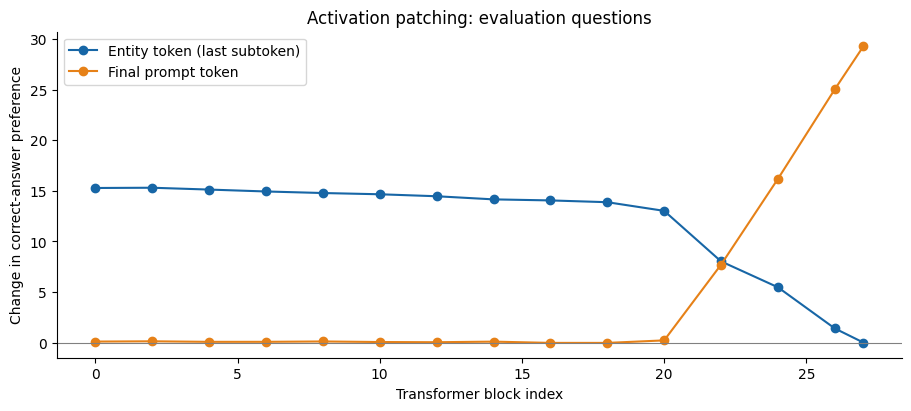

In [6]:
if result.get("patching", {}).get("rows"):
    patch = result["patching"]
    rows = patch["rows"]
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for site, label, color in [("entity", "Entity token (last subtoken)", "#1766a6"),
                                ("last_prompt", "Final prompt token", "#e68118")]:
        site_rows = [r for r in rows if r.get("site", "last_prompt") == site and r["split"] == "evaluation"]
        if site_rows:
            indices = sorted({r["layer"] for r in site_rows})
            means = [np.mean([r["effect"] for r in site_rows if r["layer"] == i]) for i in indices]
            ax.plot(indices, means, "o-", color=color, label=label)
    ax.axhline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Transformer block index", ylabel="Change in correct-answer preference",
           title="Activation patching: evaluation questions")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    
else:
    print("Run the model or import saved results to display patching effects.")

## 5. Build a positive-minus-negative sentiment vector

We have 24 manually authored pairs of positive and negative review sentences. Each pair concerns the same topic. For each sentence, we feed the plain text `Review: {sentence}` to the model and extract the final token's block output.

At each candidate block, compute

$$d = \frac{1}{N}\sum_i (h_i^{+} - h_i^{-}), \qquad h' = h + \alpha d.$$

We use the raw mean difference: **alpha = 1 adds one mean-difference vector**. Negative alpha reverses the intervention.

In [7]:
# Just showing off two examples of the sentiment pairs we are using to construct the steering vectors
print(data["sentiment_pairs"][0]["positive"], "|", data["sentiment_pairs"][0]["negative"])
print(data["sentiment_pairs"][1]["positive"], "|", data["sentiment_pairs"][1]["negative"])

if RUN_MODEL:
    differences = {layer: [] for layer in steering_layers}
    
    for pair in data["sentiment_pairs"]:
        positive = tokenizer.encode("Review: " + pair["positive"], add_special_tokens=False)
        negative = tokenizer.encode("Review: " + pair["negative"], add_special_tokens=False)

        # For both prompt we capture the hidden states at the last token of the completed sentence for each of the steering layers
        pos_states = capture_states(positive, steering_layers)
        neg_states = capture_states(negative, steering_layers)

        # We store each difference in the hidden states for each layer, which will later be averaged to create the steering vectors
        for layer in steering_layers:
            differences[layer].append(pos_states[layer] - neg_states[layer])

    # Here we compute the average difference for each layer, which will serve as our steering vector for that specific layer.
    vectors = {layer: torch.stack(values).mean(dim=0) for layer, values in differences.items()}
    result["vector_construction"] = {
        "pairs": len(data["sentiment_pairs"]), "prefix": "Review: ", "site": "last token of completed sentence",
        "vector_norms": {str(layer): float(vector.norm()) for layer, vector in vectors.items()},
    }
    
    RESULTS.mkdir(exist_ok=True)
    np.savez_compressed(RESULTS / "steering_vectors.npz", **{f"block_{layer}": vector.numpy() for layer, vector in vectors.items()})
    save_results()
    
    print("Vector norms:", result["vector_construction"]["vector_norms"])

The food was delicious and the service was excellent. | The food was terrible and the service was awful.
The meal was delightful and worth every penny. | The meal was disappointing and a waste of money.


## 6. Choose a steering block on development prompts

On the restaurant and product prompts, compare strengths -1, 0, and +1 at three candidate blocks. Choose the block with the largest mean increase in positive-candidate preference from -1 to +1. Keep this block fixed for hotel, film, museum, and library prompts.

In [8]:
if RUN_MODEL:
    development = []

    # We prompt the model simply requesting a review
    for prompt in [p for p in data["review_prompts"] if p["split"] == "development"]:
        ids = chat_ids(prompt["prompt"])

        # At each steering layer, we apply the steering vector with different strengths
        for layer in steering_layers:
            for alpha in (-1.0, 0.0, 1.0):
                scores = candidate_scores(ids, prompt["positive_candidate"], prompt["negative_candidate"], layer, steering_edit(vectors[layer], alpha, len(ids)))
                development.append({"id": prompt["id"], "layer": layer, "alpha": alpha, **scores})

    development_effects = {}
    for layer in steering_layers:
        effects = []

        # We compute the effect of steering by taking the difference in preference scores between alpha=1.0 and alpha=-1.0 
        for prompt in [p for p in data["review_prompts"] if p["split"] == "development"]:
            scores = {r["alpha"]: r["preference"] for r in development if r["id"] == prompt["id"] and r["layer"] == layer}
            effects.append(scores[1.0] - scores[-1.0])

        development_effects[layer] = float(np.mean(effects))
    
    steering_layer = max(steering_layers, key=lambda layer: development_effects[layer])
    result["steering_development"] = {"rows": development, "effects": development_effects,
                                      "selected_layer": steering_layer}
    save_results()

if "steering_development" in result:
    dev = result["steering_development"]
    print("Development effects (+1 minus -1):", dev["effects"])
    print("Frozen block for evaluation:", dev["selected_layer"])

Development effects (+1 minus -1):

 {'7': 1.8490276336669922, '14': 22.32266902923584, '21': 14.922130107879639}
Frozen block for evaluation: 14


## 7. Steering on new topics: subtract, do nothing, add

The review prompts do not specify positive or negative sentiment. Keep the prompt, weights, and decoding fixed, and vary only the vector strength: negative, zero, and positive values.

The plot measures changes in preference for two authored candidate sentences. Read the generated reviews as well: do sentiment, coherence, and topic change? The direction and strengths are interventions to evaluate, not guaranteed outcomes.

In [9]:
if RUN_MODEL:
    direction = vectors[steering_layer]
    steering_rows = []

    # Earlier, we used the development set to determine which layer to apply the steering vector. Now, we evaluate the effect of steering on a separate evaluation set.
    for prompt in [p for p in data["review_prompts"] if p["split"] == "evaluation"]:
        ids = chat_ids(prompt["prompt"])

        # How much difference there is between the positive and negative candidate answers for the original prompt, without any steering applied?
        baseline = candidate_scores(ids, prompt["positive_candidate"], prompt["negative_candidate"])

        # We leverage more alpha values to see how the strength of the steering vector affects the model's preference
        for alpha in STRENGTHS:
            edit = steering_edit(direction, alpha, len(ids))
            scores = candidate_scores(ids, prompt["positive_candidate"], prompt["negative_candidate"], steering_layer, edit)
            steering_rows.append({"id": prompt["id"], "prompt": prompt["prompt"], "alpha": alpha, **scores, 
                                  # "effect" shows how much the steering has influenced the model's preference for the positive candidate over the negative candidate.
                                  "effect": scores["preference"] - baseline["preference"],
                                  "generation": generate_text(ids, steering_layer, edit)})
            
        print("Steered:", prompt["id"])
        
    result["steering_evaluation"] = {"rows": steering_rows, "layer": steering_layer}
    save_results()

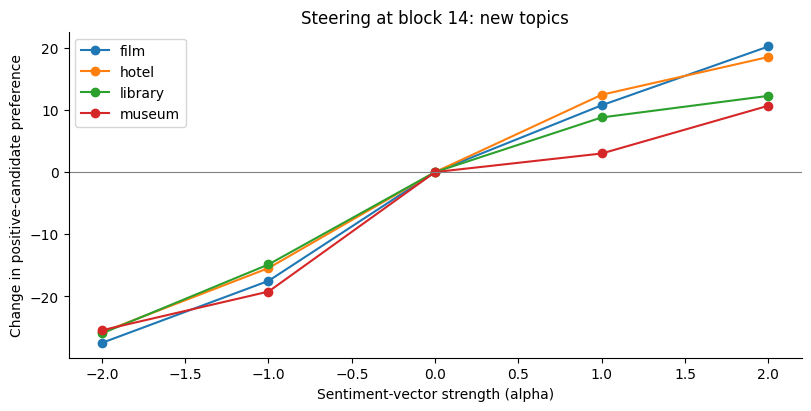


eval_hotel | alpha=-2
The hotel I stayed at was absolutely terrible. The rooms were dirty and unclean. The service I received from the staff was not worth even having their presence. It's one of the best hotels in the world. Every single person I spoke

eval_hotel | alpha=-1
The hotel was quite dirty with mold on the walls and furniture, making it uncomfortable to stay in. The staff were unprofessional, not willing to assist guests or fix broken amenities. Overall, this experience was terrible. I would not recommend staying

eval_hotel | alpha=+0
The hotel I stayed at was clean and well-maintained, with spacious rooms that were comfortable to stay in. The friendly and attentive staff made my stay enjoyable, always ready to assist me with any questions or concerns.

eval_hotel | alpha=+1
The hotel I stayed at was clean and spacious with comfortable beds that were perfect for my stay. The staff were very friendly and attentive to our needs, making us feel like family.

eval_hotel | alph

In [10]:
if result.get("steering_evaluation", {}).get("rows"):
    steering = result["steering_evaluation"]

    strengths = sorted({r["alpha"] for r in steering["rows"]})
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    
    for qid in sorted({r["id"] for r in steering["rows"]}):
        scores = {r["alpha"]: r["effect"] for r in steering["rows"] if r["id"] == qid}
        ax.plot(strengths, [scores[a] for a in strengths], "o-", label=qid.removeprefix("eval_"))
    
    ax.axhline(0, color="gray", linewidth=.8)
    ax.set(
        xlabel="Sentiment-vector strength (alpha)",
        # Y-axis shows the change in log-probability margin (positive vs. negative candidate) relative to baseline (alpha=0):
        # > 0 means steering shifted preference toward the positive candidate; < 0 means it shifted toward the negative candidate.
        ylabel="Change in positive-candidate preference",
        title=f"Steering at block {steering['layer']}: new topics"
    )
    
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    
    plt.show()
    
    for row in steering["rows"]:
        print(f"\n{row['id']} | alpha={row['alpha']:+g}")
        print(row["generation"]["text"])
else:
    print("Run the model or import saved results to display steering outputs.")

## 8. What can we conclude?

- **Patching:** replacing an activation at the entity or final prompt position can affect the answer. The two locations let us compare an earlier source of information with a later output position. 
- **Steering:** a direction constructed from contrasting review sentences can influence sentiment on new topics.

Methods:
* Activation patching: [Heimersheim & Nanda](https://arxiv.org/abs/2404.15255); 
* Contrastive activation addition: [Rimsky et al.](https://aclanthology.org/2024.acl-long.828/).

## 9. Save and replay

Export the scores, generated text, vectors, and input data as `practicum2_upload.zip`. To replay on a CPU, set `RUN_MODEL = False` and `IMPORT_RESULTS = True`, then upload the ZIP in Colab or point `RESULTS_ARCHIVE` to it locally.

The supplied archive includes measured results for both patching locations and sentiment steering; replay does not require another model run.

In [11]:
if RUN_MODEL and result:
    save_results()
    export_path = Path("practicum2_upload.zip")
    with zipfile.ZipFile(export_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(RESULTS / "results.json", "results.json")
        if (RESULTS / "steering_vectors.npz").exists():
            archive.write(RESULTS / "steering_vectors.npz", "steering_vectors.npz")
        archive.write(DATA / "practicum2.json", "data/practicum2.json")
    print("Saved:", export_path)
    try:
        from google.colab import files
    except ImportError:
        display(Markdown(f"[Download measured results]({export_path.as_posix()})"))
    else:
        files.download(str(export_path))
elif result:
    print("Replay complete. Original measured results were not overwritten.")
else:
    print("Nothing to export yet: no pretrained-model pilot has been run or imported.")

Replay complete. Original measured results were not overwritten.
